<a href="https://colab.research.google.com/github/sanjana0422/marketing_data/blob/main/marketing_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(56000, 28) ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Response               0
Complain               0
Country                0
dtype: int64


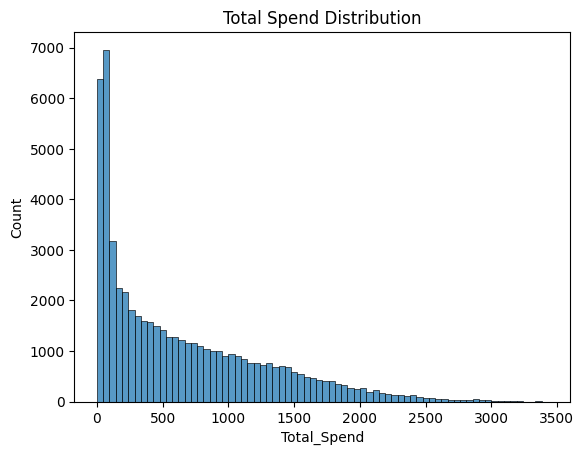

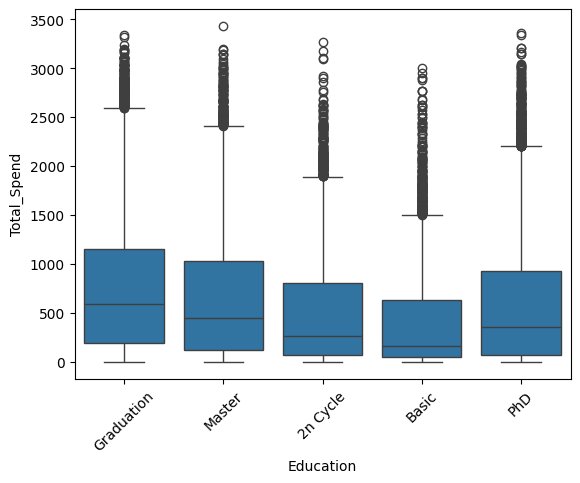

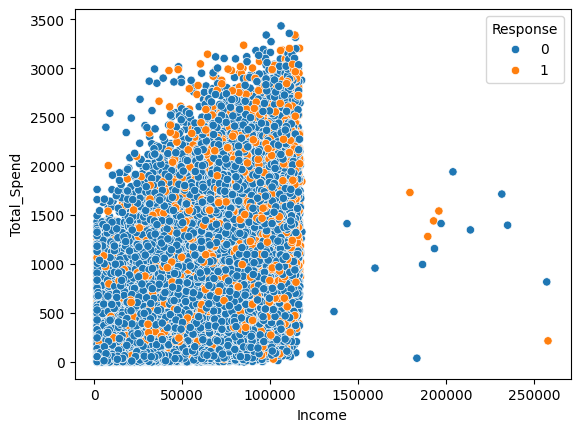

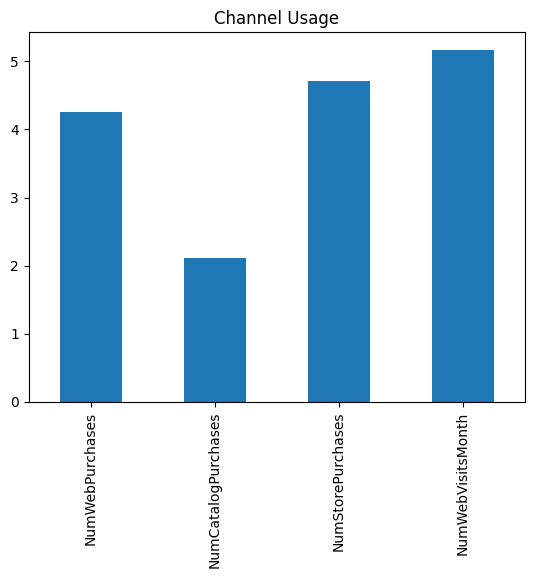

                  mean  count       sum
Education                              
2n Cycle    511.298190   5966   3050405
Basic       416.460306   4182   1741637
Graduation  747.349369  22741  16995472
Master      648.498670  10530   6828691
PhD         575.672125  12581   7242531
High Spender cutoff 90th percentile: 1564.0


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. LOADING ---
def load_data(path):
    df = pd.read_csv('marketing_campaign_data.csv')
    return df

df = load_data('marketing_campaign_data.csv')
print(df.shape, df.isnull().sum())

# --- 2. CLEANING ---
# Handle Dt_Customer
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
# Handle Income missing - median
df['Income'] = df['Income'].fillna(df['Income'].median())
# Remove unrealistic Age > 90 or < 18
df['Age'] = 2026 - df['Year_Birth']
df = df[(df['Age'] >= 18) & (df['Age'] <= 90)]

# Derived Columns
spend_cols = ['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']
df['Total_Spend'] = df[spend_cols].sum(axis=1)
df['Total_Purchases'] = df['NumWebPurchases']+df['NumCatalogPurchases']+df['NumStorePurchases']
df['Children'] = df['Kidhome']+df['Teenhome']
df['Customer_Tenure_Days'] = (pd.Timestamp('2026-01-01') - df['Dt_Customer']).dt.days
df['Income_Band'] = pd.cut(df['Income'], bins=[0,30000,75000,150000,1000000], labels=['Low','Medium','High','Very High'])
df['Age_Band'] = pd.cut(df['Age'], bins=[0,30,45,60,100], labels=['Young <30','Middle 30-45','Mature 45-60','Senior 60+'])

# --- 3. EDA ---
# Univariate
sns.histplot(df['Total_Spend'])
plt.title('Total Spend Distribution'); plt.show()

# Bivariate: Spending vs Age, Income, Marital, Country
sns.boxplot(x='Education', y='Total_Spend', data=df); plt.xticks(rotation=45); plt.show()
sns.scatterplot(x='Income', y='Total_Spend', data=df, hue='Response'); plt.show()

# Channel usage
channel_cols = ['NumWebPurchases','NumCatalogPurchases','NumStorePurchases','NumWebVisitsMonth']
df[channel_cols].mean().plot(kind='bar', title='Channel Usage'); plt.show()

# --- 4. RULE-BASED SEGMENTATION ---
# 90th percentile for High Spender
spend_90 = df['Total_Spend'].quantile(0.90)

def assign_segments(row):
    return {
        'Is_High_Income': 1 if row['Income'] > 75000 else 0,
        'Is_Young': 1 if row['Age'] < 30 else 0,
        'Is_Campaign_Responder': row['Response'],
        'Is_High_Web_Engagement': 1 if row['NumWebVisitsMonth'] > 5 else 0,
        'Is_Family': 1 if row['Children'] > 0 else 0,
        'Is_High_Spender': 1 if row['Total_Spend'] > spend_90 else 0
    }

seg_df = pd.DataFrame([assign_segments(r) for _, r in df.iterrows()])
df = pd.concat([df, seg_df], axis=1)

# Segment summary
segment_summary = df.groupby('Education')['Total_Spend'].agg(['mean','count','sum'])
print(segment_summary)

# Save cleaned for SQL & Dashboard
df.to_csv('cleaned_marketing_data.csv', index=False)
print(f"High Spender cutoff 90th percentile: {spend_90}")

In [13]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.set_page_config(page_title="Marketing Dashboard", layout="wide")
st.title("📊 Marketing Campaign Dashboard")

@st.cache_data
def load_data():
    df = pd.read_csv('cleaned_marketing_data.csv')
    df['Total_Spend'] = df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
    return df

df = load_data()

# --- FILTERS ---
st.sidebar.header("🔍 Filters")
country = st.sidebar.multiselect("Country", df['Country'].unique(), default=list(df['Country'].unique()))
education = st.sidebar.multiselect("Education", df['Education'].unique(), default=list(df['Education'].unique()))
age = st.sidebar.multiselect("Age Band", df['Age_Band'].unique(), default=list(df['Age_Band'].unique()))

fdf = df[(df['Country'].isin(country)) & (df['Education'].isin(education)) & (df['Age_Band'].isin(age))]

# --- KPIs ---
c1, c2, c3 = st.columns(3)
c1.metric("Total Customers", f"{len(fdf):,}")
c2.metric("Response Rate", f"{fdf['Response'].mean()*100:.2f}%")
c3.metric("Avg Spend", f"${fdf['Total_Spend'].mean():,.0f}")

# --- CHART 1: By Education ---
st.subheader("1. Response Rate by Education (%)")
fig1, ax1 = plt.subplots()
fdf.groupby('Education')['Response'].mean().mul(100).plot(kind='bar', color='skyblue', ax=ax1)
ax1.set_ylabel("Response %")
st.pyplot(fig1)

# --- CHART 2: By Country ---
st.subheader("2. Response Rate by Country (%)")
fig2, ax2 = plt.subplots()
fdf.groupby('Country')['Response'].mean().mul(100).plot(kind='bar', color='orange', ax=ax2)
ax2.set_ylabel("Response %")
st.pyplot(fig2)

# --- CHART 3: By Age Band ---
st.subheader("3. Avg Spend by Age Band")
fig3, ax3 = plt.subplots()
fdf.groupby('Age_Band')['Total_Spend'].mean().plot(kind='bar', color='green', ax=ax3)
ax3.set_ylabel("Avg Spend")
st.pyplot(fig3)

# --- TABLE ---
st.subheader("Segment-Level Summary")
summary = fdf.groupby(['Education','Marital_Status','Country']).agg(
    customers=('ID','count'),
    response_rate=('Response','mean'),
    avg_spend=('Total_Spend','mean')
).reset_index()
st.dataframe(summary, use_container_width=True)

Overwriting app.py


In [5]:
!pip install plotly -q
import pandas as pd
import plotly.express as px

df = pd.read_csv('cleaned_marketing_data.csv')
print(df.shape)
print(df.columns.tolist())

(56000, 41)
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Country', 'Age', 'Total_Spend', 'Total_Purchases', 'Children', 'Customer_Tenure_Days', 'Income_Band', 'Age_Band', 'Is_High_Income', 'Is_Young', 'Is_Campaign_Responder', 'Is_High_Web_Engagement', 'Is_Family', 'Is_High_Spender']


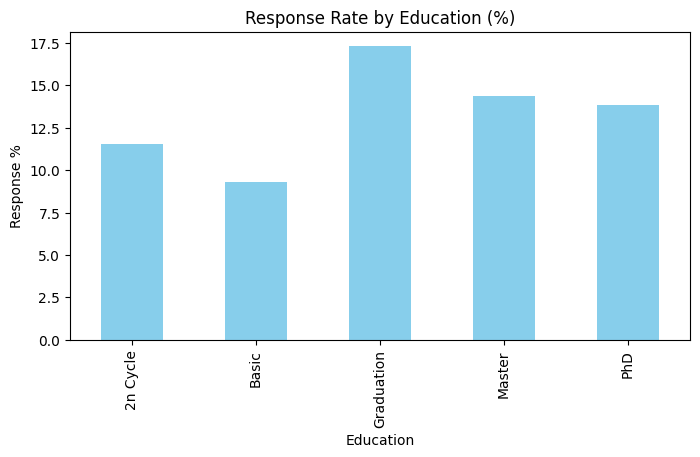

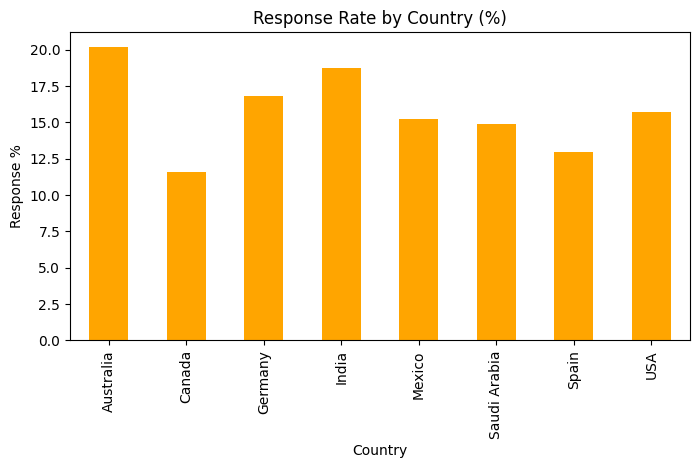

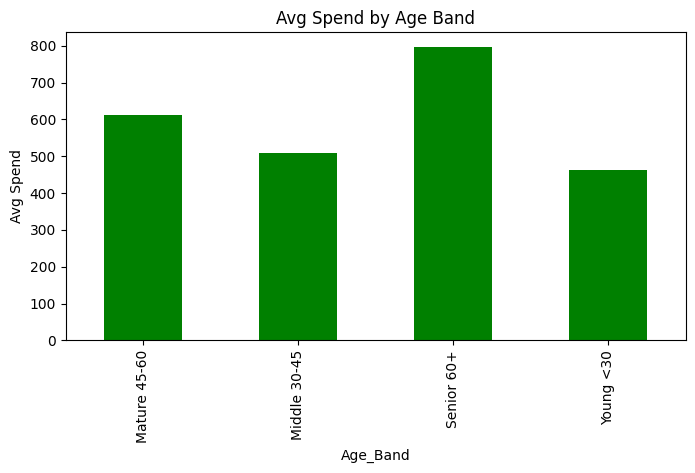

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
df.groupby('Education')['Response'].mean().mul(100).plot(kind='bar', color='skyblue')
plt.title('Response Rate by Education (%)')
plt.ylabel('Response %')
plt.show()

plt.figure(figsize=(8,4))
df.groupby('Country')['Response'].mean().mul(100).plot(kind='bar', color='orange')
plt.title('Response Rate by Country (%)')
plt.ylabel('Response %')
plt.show()

plt.figure(figsize=(8,4))
df.groupby('Age_Band')['Total_Spend'].mean().plot(kind='bar', color='green')
plt.title('Avg Spend by Age Band')
plt.ylabel('Avg Spend')
plt.show()

In [14]:
!pkill -9 streamlit
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --server.enableWebsocketCompression false --server.headless true > /tmp/log 2>&1 &
import time
time.sleep(8)
!cat /tmp/log



2026-11-07 11:00:45.825 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.168.17.72:8501



In [15]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=900)

<IPython.core.display.Javascript object>